# Induction of Decision Trees: ID3 from scratch, on real data
**Paper:** Quinlan, J. R. (1986). *Induction of decision trees.* Machine Learning, 1(1), 81–106. https://doi.org/10.1007/BF00116251
**Course:** MA30235 / MA60215 Advanced Machine Learning, IIT Kharagpur, Autumn 2026 · **Group:** _Name (Roll no.), …_

This notebook implements every mechanism in the paper:
* information gain and the divide-and-conquer tree, with windowing (Section 4);
* the chi-square noise test (Section 5);
* unknown attribute values (Section 6);
* the gain ratio, binary value-subset tests and continuous thresholds (Section 7).

It then studies the method on **seven real UCI datasets**, including a chess endgame, the closest public relative of the paper's chess task, and three datasets with genuinely missing values. **Simulated data** from a known tree are used only for sanity checks. The project's two required experiments are **depth control** and **noisy inputs**.

**How to run.** *Colab:* upload the `id3-project` folder to My Drive, open this notebook and choose *Run all*. Alternatively, clone `https://github.com/Vinayak069/id3-decision-trees`. *Laptop:* `pip install -r requirements.txt` and `jupyter notebook`. Set `QUICK = True` for a 2-minute demo (5 instead of 20 repetitions).

In [1]:
import os, sys
try:                                       # Colab: mount Drive (or clone the GitHub repo instead)
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/id3-project')
except ImportError:
    pass
sys.path.insert(0, os.getcwd())
QUICK = False
REPS = 5 if QUICK else 20
import numpy as np, pandas as pd
from IPython.display import Image, display
from concurrent.futures import ProcessPoolExecutor
import id3, experiments as E
E.REPS = REPS
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
print('working directory:', os.getcwd(), '| repetitions:', REPS)

working directory: /mnt/attach/project-files/id3-project | repetitions: 20


## 1. The key equations (Sections 4, 5, 7)
A set $C$ with class counts $c_1,\dots,c_K$ ($K=2$ in the paper) needs $I(C)=-\sum_k \frac{c_k}{|C|}\log_2\frac{c_k}{|C|}$ bits to identify the class of an object. Testing attribute $A$ splits $C$ into $C_1,\dots,C_v$, and

$$E(A)=\sum_{i=1}^{v}\frac{|C_i|}{|C|}\,I(C_i),\qquad \text{gain}(A)=I(C)-E(A)=\text{MI}(A;\text{class})\ \ (\text{footnote 3}).$$

Section 7 divides by the information in the attribute's own value to remove the bias towards many-valued attributes:

$$IV(A)=-\sum_i\frac{|C_i|}{|C|}\log_2\frac{|C_i|}{|C|},\qquad \text{gain ratio}(A)=\frac{\text{gain}(A)}{IV(A)}.$$

Section 5 tests $A$ only if the independence of $A$ and the class is rejected:

$$\chi^2=\sum_{i,k}\frac{(c_{ik}-c'_{ik})^2}{c'_{ik}},\qquad c'_{ik}=c_k\frac{|C_i|}{|C|},\qquad \chi^2\sim\chi^2_{(v-1)(K-1)}\ \text{under}\ H_0.$$

In [2]:
import inspect
for f in (id3.entropy, id3.information_gain, id3.intrinsic_value, id3.chi_square):
    print(inspect.getsource(f))

def entropy(counts) -> float:
    """I(p, n) generalised to K classes: -sum_k (c_k/N) log2 (c_k/N), with 0 log 0 = 0."""
    c = np.asarray(counts, dtype=float)
    total = c.sum()
    if total <= 0:
        return 0.0
    q = c[c > 0] / total
    return float(-(q * np.log2(q)).sum())

def information_gain(table) -> float:
    """gain(A) = I(C) - E(A)."""
    t = np.asarray(table, dtype=float)
    return entropy(t.sum(axis=0)) - expected_information(t)

def intrinsic_value(table) -> float:
    """IV(A) = -sum_i (|C_i|/|C|) log2 (|C_i|/|C|), the information in the attribute's value."""
    return entropy(np.asarray(table, dtype=float).sum(axis=1))

def chi_square(table):
    """Quinlan's Section-5 statistic sum_i sum_k (c_ik - c'_ik)^2 / c'_ik and its p-value.

    c'_ik = c_k * |C_i| / |C| is the count expected if A were irrelevant to the class.
    Degrees of freedom (v-1)(K-1); the paper's two-class case gives v-1.
    """
    t = np.asarray(table, dtype=float)
    t = t[t.sum(axis=1

## 2. Verification on the paper's own example (Table 1)
The paper reports $I(9,5)=0.940$, gains 0.246 / 0.029 / 0.151 / 0.048, $IV(\text{outlook})=1.578$ and gain ratios 0.156 vs 0.151. Our values agree to the paper's rounding, and the tree is the paper's Figure 2.

,attribute,E(A) bits,gain bits,paper gain,IV bits,paper IV,gain ratio,paper gain ratio,chi2,p-value
0,outlook,0.6935,0.2467,0.246,1.5774,1.578,0.1564,0.156,3.5467,0.1698
1,temperature,0.9111,0.0292,0.029,1.5567,NaN,0.0188,NaN,0.5704,0.7519
2,humidity,0.7885,0.1518,0.151,1.0000,1.000,0.1518,0.151,2.8000,0.0943
3,windy,0.8922,0.0481,0.048,0.9852,NaN,0.0488,NaN,0.9333,0.3340


outlook = overcast: P  (n=4)
outlook = rain:
|   windy = false: P  (n=3)
|   windy = true: N  (n=2)
outlook = sunny:
|   humidity = high: N  (n=3)
|   humidity = normal: P  (n=2)


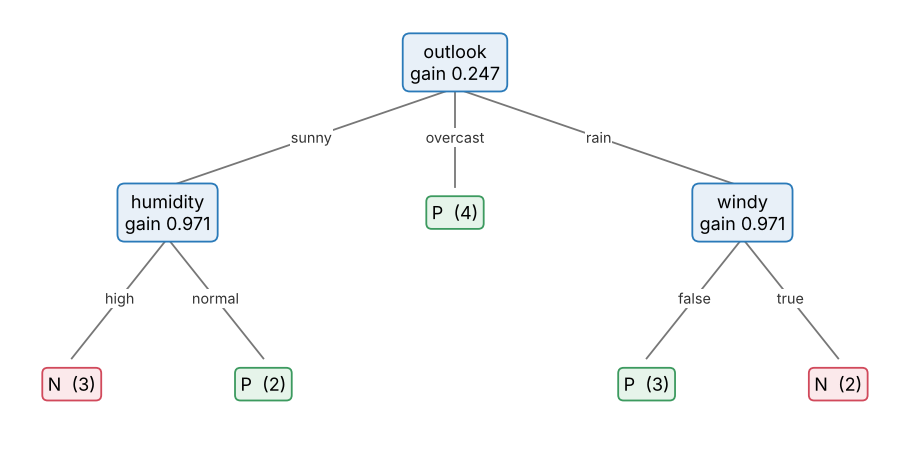

prediction: ['P']  P(class) = {np.str_('N'): np.float64(0.3571), np.str_('P'): np.float64(0.6429)}


In [3]:
X, y = E.load('weather')
gains, tree = E.e1_weather(); E.draw_weather_tree(tree)
display(gains); print(tree.export_text()); display(Image('figures/weather_tree.png'))
# Live demo: an unknown outlook is sent down all three branches with weights 5/14, 4/14, 5/14 (Section 6)
new = pd.DataFrame([{'outlook':'?','temperature':'hot','humidity':'high','windy':'false'}])
print('prediction:', tree.predict(new), ' P(class) =', dict(zip(tree.classes_, tree.predict_proba(new)[0].round(4))))

In [4]:
# 15 unit tests check the paper's numbers and claims (gain = mutual information, refinement never lowers
# gain, unknowns only lower gain, the 'unknown as a value' anomaly, chi-square = scipy, recovery of a known tree)
!python -m pytest -q -p no:cacheprovider tests

.

.....

.

...

.

....                                                          [100%]
15 passed in 1.11s


## 3. Real data
Each real dataset tests a different part of the paper. Simulated data appear only in Section 9 (sanity checks).

In [5]:
display(E.data_summary())

,dataset,file,type,objects,attributes,values per attribute,classes,unknown values
0,Saturday mornings (paper Table 1),real/weather_quinlan1986.csv,real,14,4,2-3,"P 9, N 5",0
1,Chess endgame KR vs KP (UCI),real/chess_kr_vs_kp.csv,real,3196,36,2-3,"won 1669, nowin 1527",0
2,Mushroom (UCI),real/mushrooms.csv,real,8124,22,1-12,"e 4208, p 3916",2480
3,Congressional votes 1984 (UCI),real/house_votes_84.csv,real,435,16,3-3,"democrat 267, republican 168",392
4,Car Evaluation (UCI),real/car_evaluation.csv,real,1728,6,3-4,"unacc 1210, acc 384, good 69, vgood 65",0
5,Tic-tac-toe endgame (UCI),real/tic_tac_toe.csv,real,958,9,3-3,"positive 626, negative 332",0
6,"Breast cancer, Ljubljana (UCI)",real/breast_cancer_ljubljana.csv,real,286,9,2-11,"no-recurrence-events 201, recurrence-events 85",9
7,"Breast cancer, Wisconsin (UCI)",real/breast_cancer_wisconsin.csv,real,569,30,continuous,"benign 357, malignant 212",0
8,Simulated: known depth-3 tree,simulated/sim_tree_2000.csv,simulated,2000,10,3-3,"P 1178, N 822",0
9,Simulated + 150-valued id_code,simulated/sim_with_id_600.csv,simulated,600,11,3-150,"P 339, N 261",0


| Dataset | What it tests |
|---|---|
| **Chess KRvKP** (Shapiro, UCI) | A chess endgame with 36 mostly binary attributes. This is the closest public relative of the paper's chess task. |
| **Mushroom** | 22 attributes with up to 12 values; `stalk_root` is missing for 30 % of records |
| **Congressional votes 1984** | 392 genuinely missing votes ('?'); a single attribute nearly decides the class |
| **Car Evaluation** | Multi-class, unbalanced; multi-way splits fragment the data |
| **Tic-tac-toe endgame** | A disjunctive concept that multi-way splits express badly |
| **Breast cancer, Ljubljana** | The Bratko-group medical domain used by ASSISTANT; it is noisy, with weak signal |
| **Breast cancer, Wisconsin** | 30 continuous attributes, split with Section 7's midpoint thresholds |

## 4. Benchmark: ID3 variants against CART
We use 20 stratified 70/30 splits, with the same splits for every method. Differences are tested with the Nadeau–Bengio *corrected* resampled t-test, because overlapping training sets make the plain paired t-test too optimistic.

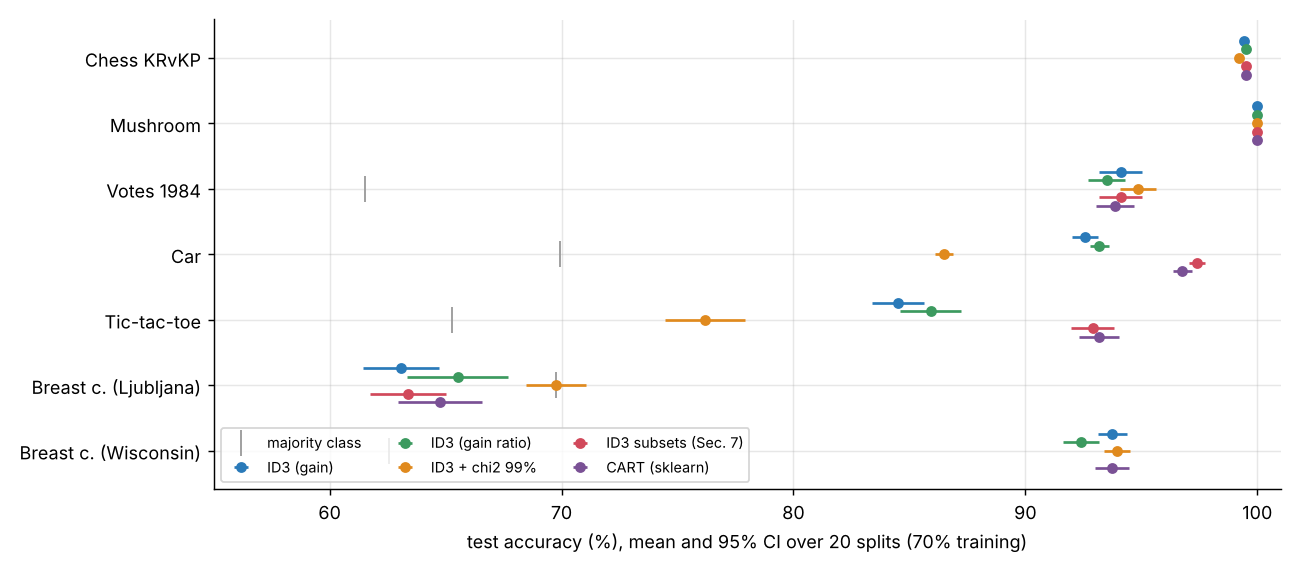

dataset,chess,mushroom,votes,car,tictactoe,bcl,wdbc
model,,,,,,,
CART (sklearn),99.5 ± 0.1,100.0 ± 0.0,93.8 ± 0.4,96.8 ± 0.2,93.2 ± 0.4,64.8 ± 0.9,93.7 ± 0.4
ID3 (gain ratio),99.5 ± 0.1,100.0 ± 0.0,93.5 ± 0.4,93.2 ± 0.2,85.9 ± 0.7,65.5 ± 1.1,92.4 ± 0.4
ID3 (gain),99.4 ± 0.1,100.0 ± 0.0,94.1 ± 0.5,92.6 ± 0.3,84.5 ± 0.6,63.1 ± 0.8,93.7 ± 0.3
ID3 + chi2 99%,99.2 ± 0.1,100.0 ± 0.0,94.8 ± 0.4,86.5 ± 0.2,76.2 ± 0.9,69.8 ± 0.7,93.9 ± 0.3
ID3 subsets (Sec. 7),99.5 ± 0.1,100.0 ± 0.0,94.1 ± 0.5,97.4 ± 0.2,92.9 ± 0.5,63.4 ± 0.8,NaN
ID3 subsets + chi2 99%,99.3 ± 0.1,100.0 ± 0.0,94.8 ± 0.4,95.2 ± 0.2,89.1 ± 1.2,68.9 ± 0.9,NaN
Majority class,52.2 ± 0.0,51.8 ± 0.0,61.5 ± 0.0,69.9 ± 0.0,65.3 ± 0.0,69.8 ± 0.0,62.6 ± 0.0


,dataset,comparison,mean_diff_pts,wins,ties,losses,t,p_value
15,car,ID3 subsets (Sec. 7) - ID3 (gain),4.8362,20,0,0,4.5739,0.0002
17,car,ID3 (gain) - CART (sklearn),-4.2004,0,0,20,-3.6959,0.0015
18,car,ID3 + chi2 99% - ID3 (gain),-6.0886,0,0,20,-8.5874,0.0000
20,tictactoe,ID3 subsets (Sec. 7) - ID3 (gain),8.4028,20,0,0,4.0112,0.0007
22,tictactoe,ID3 (gain) - CART (sklearn),-8.6806,0,0,20,-3.7562,0.0013
23,tictactoe,ID3 + chi2 99% - ID3 (gain),-8.3160,0,0,20,-3.0911,0.0060
28,bcl,ID3 + chi2 99% - ID3 (gain),6.6860,17,2,1,2.2710,0.0350


In [6]:
with ProcessPoolExecutor() as pool:
    summ, tests = E.e2_benchmark(pool, REPS)
display(Image('figures/e2_benchmark.png'))
tab = summ.assign(acc=lambda d: (100*d.acc_mean).round(1).astype(str) + ' ± ' + (100*d.acc_se).round(1).astype(str))
display(tab.pivot(index='model', columns='dataset', values='acc')[E.BENCH])
display(tests[tests.p_value < 0.05])

**Reading.**
* **Clean, deterministic concepts.** On chess and mushroom, plain ID3 is as good as CART: 99.4 % and 100 %.
* **Fragmentation.** Car Evaluation and tic-tac-toe expose ID3's weakness: multi-way splits fragment the data. Plain ID3 is 4.2 and 8.7 points behind CART, and both gaps are significant (p ≤ 0.002).
* **Section 7 subset tests.** The binary value-subset tests the paper discusses close those gaps completely. They gain +4.8 and +8.4 points over plain ID3 (p < 0.001) and are level with CART on both datasets, with trees less than half the size.
* **Noisy medical data.** On Ljubljana breast cancer, every full tree is *worse than guessing the majority class* (69.8 %). Only the χ² test reaches the majority rate; it does this by refusing almost every split, leaving 8 nodes.
* **Continuous attributes.** On Wisconsin breast cancer, midpoint thresholds make ID3 equal to CART (93.7 %).

In [7]:
with ProcessPoolExecutor() as pool:
    lc = E.e2b_learning_curve(pool, REPS)
display(lc)

,train_frac,accuracy,acc_se,nodes
0,0.02,0.8967,0.0102,18.70
1,0.05,0.9381,0.0030,30.25
2,0.10,0.9550,0.0019,41.75
3,0.20,0.9767,0.0015,57.25
4,0.40,0.9873,0.0011,76.75
5,0.70,0.9937,0.0008,86.95


Section 4 trained on 20 % of the chess positions and predicted the rest with over 84 % accuracy (715 objects, 49 attributes). On KRvKP, 20 % training already gives about 97.7 %, and 2 % (64 positions) gives about 90 %.

## 5. Depth control and the χ² level (required experiment 1)
Top row: test accuracy against `max_depth`, a control we added that is not in the paper. Bottom row: test accuracy against the χ² level α, with tree size as grey bars.

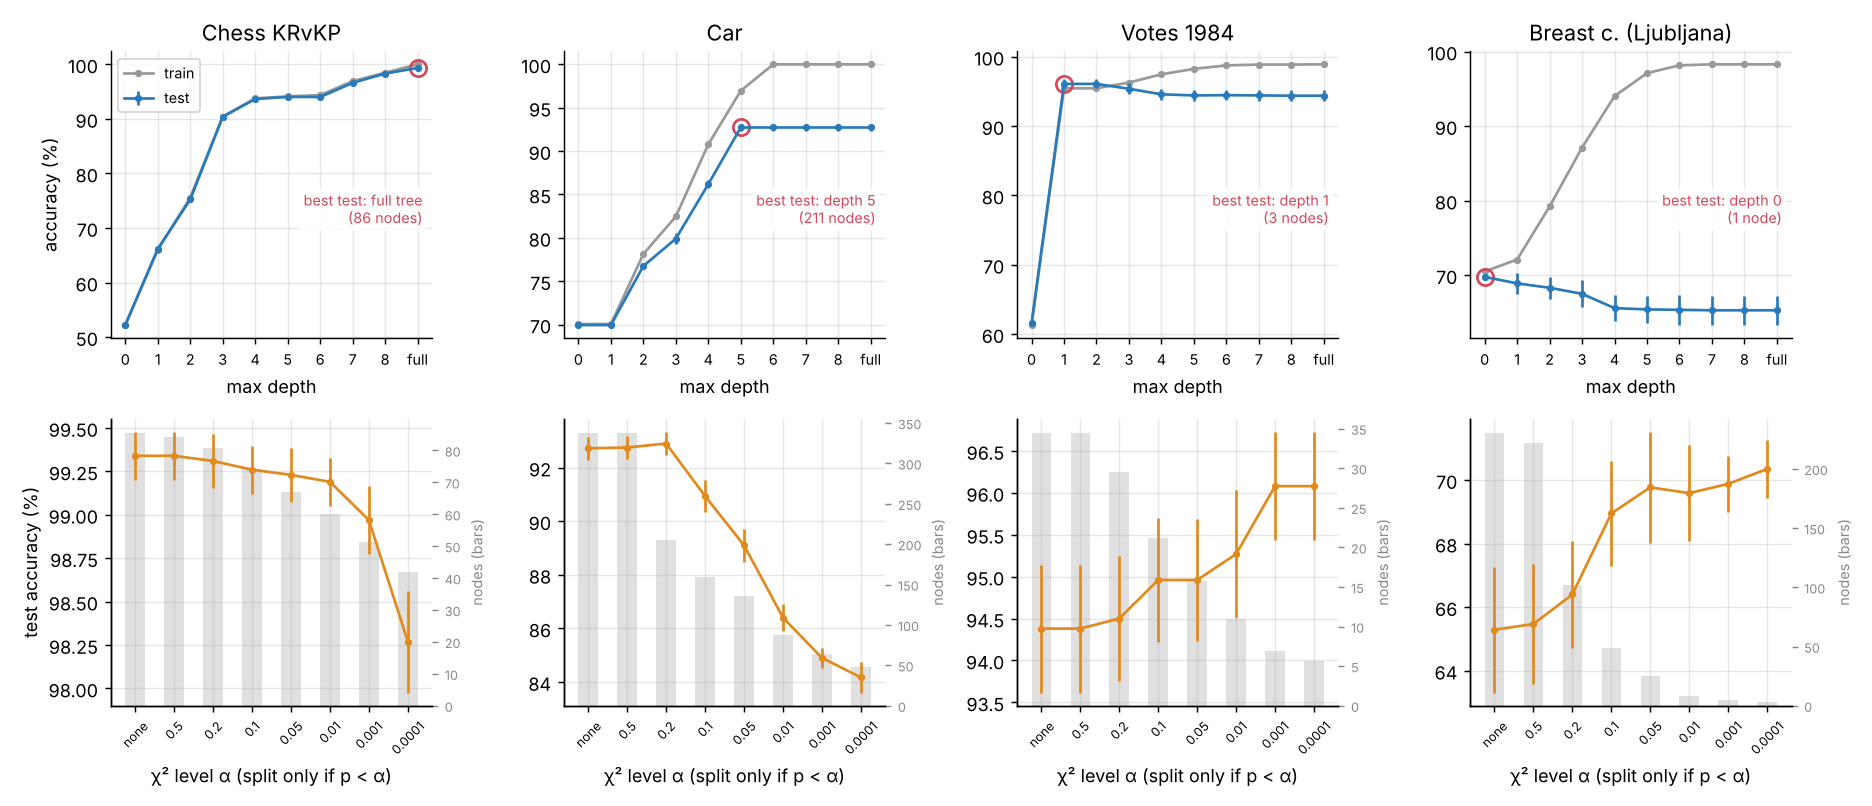

,dataset,control,value,train_acc,test_acc,test_se,nodes
0,bcl,alpha,0.0001,0.7217,0.7035,0.0047,3.30
8,bcl,depth,0.0000,0.7050,0.6977,0.0000,1.00
23,car,alpha,0.2000,0.9724,0.9290,0.0022,204.70
31,car,depth,5.0000,0.9696,0.9272,0.0022,210.65
42,chess,alpha,0.5000,0.9999,0.9934,0.0007,84.10
53,chess,depth,99.0000,1.0000,0.9934,0.0007,85.60
54,votes,alpha,0.0001,0.9544,0.9608,0.0033,5.60
63,votes,depth,1.0000,0.9544,0.9608,0.0033,3.00


In [8]:
with ProcessPoolExecutor() as pool:
    da = E.e3_depth_alpha(pool, REPS)
display(Image('figures/e3_depth_alpha_real.png'))
best = da.loc[da.groupby(['dataset','control']).test_acc.idxmax()]
display(best)

**Reading.** Whether to restrict the tree depends on whether the data are noisy:
* **Noise-free concepts (chess, car).** The full tree is best. Shallow trees or a strict α only discard real structure: on car, α = 0.01 loses 6 points.
* **Votes.** One test (`physician_fee_freeze`, 3 nodes) gives 96.1 %, against 94.4 % for the full 35-node tree.
* **Ljubljana breast cancer.** Every extra level lowers test accuracy, while training accuracy climbs to 98 %. This is textbook overfitting, and α = 10⁻⁴ (3 nodes) is the best tree.

The χ² test is the paper's automatic way to tell these situations apart. It works when samples are large, but it is too strict in small nodes, where expected counts fall below Hart's limit of about 4.

## 6. Noisy inputs: replicating Table 2 (required experiment 2)
Paper protocol: with probability *n*, a value is replaced by a random value from its domain (which may be the same value). The training part and a fresh corruption of the test part are used, 20 times per level. Noise goes into one attribute (the root attribute: `rimmx` for chess, `safety` for car), into all attributes, or into the class.

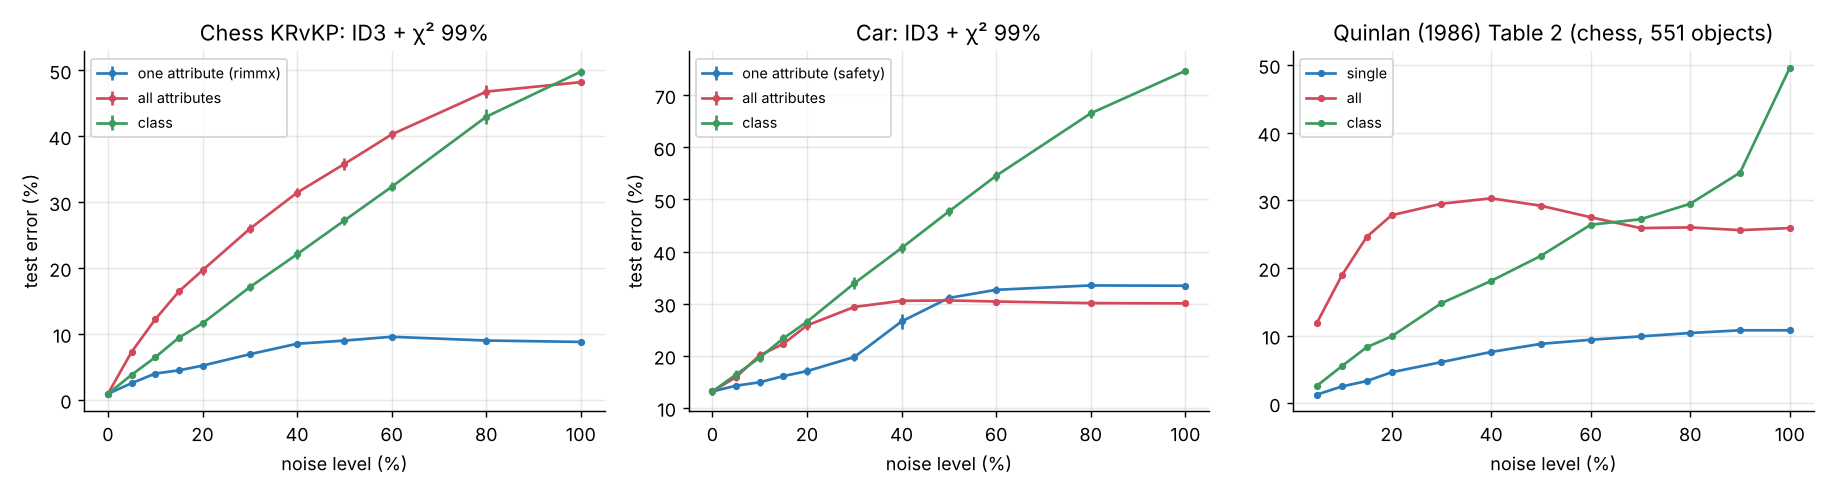

dataset   car              chess             
where     all class single   all class single
level                                        
0.00     13.2  13.2   13.2   0.9   0.9    0.9
0.05     15.9  16.4   14.3   7.3   3.8    2.5
0.10     20.1  19.6   14.9  12.2   6.4    4.0
0.15     22.3  23.3   16.1  16.4   9.4    4.5
0.20     25.8  26.5   17.1  19.7  11.6    5.2
0.30     29.4  33.9   19.8  26.0  17.1    6.9
0.40     30.6  40.7   26.6  31.4  22.1    8.5
0.50     30.6  47.7   31.1  35.8  27.2    9.0
0.60     30.4  54.6   32.7  40.3  32.3    9.6
0.80     30.1  66.5   33.5  46.8  43.0    9.0
1.00     30.1  74.7   33.4  48.2  49.8    8.8

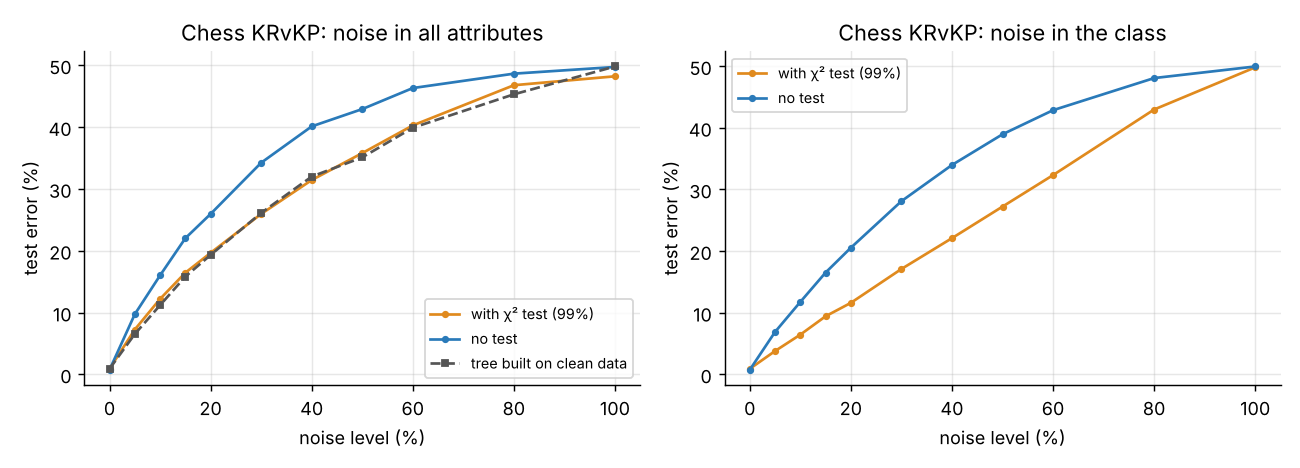

In [9]:
with ProcessPoolExecutor() as pool:
    noise = E.e4_noise(pool, REPS)
display(Image('figures/e4_noise_real.png'))
display(pd.read_csv('results/e4_table2_real.csv', header=[0,1], index_col=0).mul(100).round(1))
display(Image('figures/e4_chi2_ablation_real.png'))

**Reading.** The paper's three patterns reappear on real data.
* **Class noise.** Error grows almost linearly up to random guessing: 50 % for 2 classes, 75 % for car's 4 classes.
* **Noise in one attribute.** It saturates (9 % on chess), because the other attributes still carry the concept.
* **Noise in all attributes.** It hurts most at low levels. Then it levels off at the majority-class error once χ² finds nothing relevant: 30 % on car, 48 % on the balanced chess data. The paper's chess data were 65:35, so its curve levelled at about 26 %.
* **Without the χ² test.** Trees grow to about 2 000 nodes and the error is higher; for example, with 20 % class noise on chess, error is 20.6 % against 11.6 %.
* **Tree built on clean data.** On car, from 40 % noise onwards, the clean tree classifies noisy objects worse than a tree learned from equally noisy data. This is the paper's "moral".

**Why the curve can come down (Section 5).** A leaf that answers P with probability $p/(p+n)$ errs $2pn/(p+n)^2$; a majority leaf errs $n/(p+n)$, which is smaller.

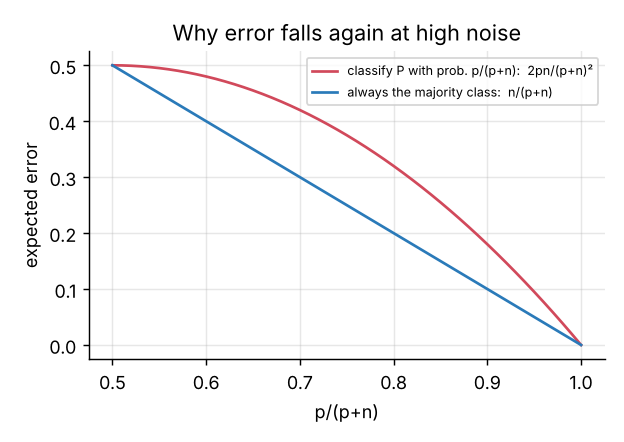

In [10]:
E.e8_theory(); display(Image('figures/e8_theory_peak.png'))

## 7. Unknown attribute values (Section 6, Figure 5)
The left panels blank values out at random. The right panel uses the genuinely missing values in the votes, mushroom and Ljubljana data. We compare three strategies: Quinlan's proportional method, treating `?` as a value, and the most-common-value rule that the paper mentions.

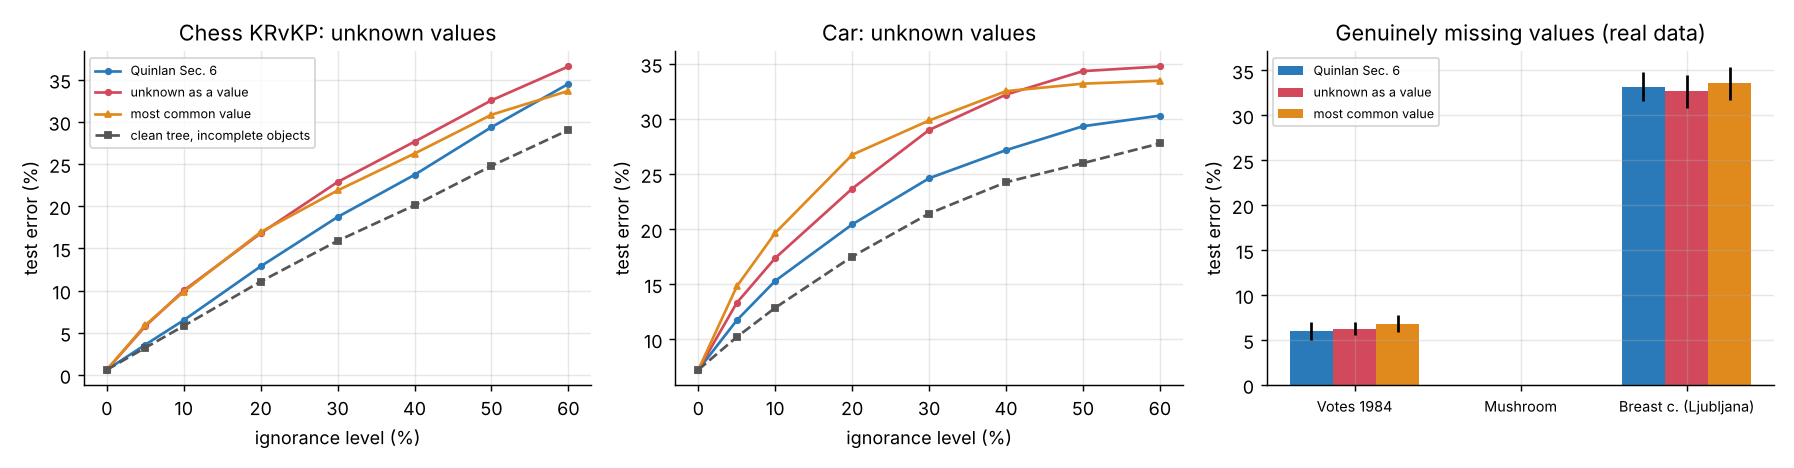

,dataset,level,error: Quinlan Sec. 6,error: unknown as a value,error: most common value,"error: clean tree, incomplete objects"
0,car,0.00,0.0724,0.0724,0.0724,0.0724
1,car,0.05,0.1173,0.1332,0.1481,0.1021
2,car,0.10,0.1531,0.1738,0.1966,0.1287
3,car,0.20,0.2043,0.2368,0.2675,0.1751
4,car,0.30,0.2462,0.2900,0.2986,0.2142
5,car,0.40,0.2717,0.3221,0.3252,0.2426
6,car,0.50,0.2934,0.3434,0.3320,0.2599
7,car,0.60,0.3030,0.3476,0.3347,0.2778
8,chess,0.00,0.0061,0.0061,0.0061,0.0061
9,chess,0.05,0.0358,0.0578,0.0591,0.0322


,dataset,Quinlan Sec. 6 (mean),Quinlan Sec. 6 (se),unknown as a value (mean),unknown as a value (se),most common value (mean),most common value (se)
0,votes,0.940,0.0049,0.9377,0.0037,0.9319,0.0049
1,mushroom,1.000,0.0000,1.0000,0.0000,1.0000,0.0000
2,bcl,0.668,0.0082,0.6733,0.0095,0.6645,0.0092


In [11]:
with ProcessPoolExecutor() as pool:
    ign, realmiss = E.e5_unknown(pool, REPS)
display(Image('figures/e5_unknown_real.png'))
display(ign); display(realmiss)

**Reading.**
* **Random blanking.** Degradation is gradual, as in Figure 5. Quinlan's method has the lowest error of the three strategies up to 50 % ignorance on chess, and at every level on car. At 30 % ignorance on car, it errs 24.6 % against 29.0 % and 29.9 %.
* **Genuinely missing values.** The three strategies are statistically indistinguishable. The missing values are few (votes, Ljubljana) or sit in an attribute the tree hardly needs (mushroom).

## 8. Windowing (Section 4)

In [12]:
display(E.e7_windowing())

,dataset,method,objects_used,nodes,train_errors,test_accuracy,seconds
0,chess,direct,2237,85,0,0.9885,0.2204
1,chess,windowing (100 + 50 per round),304,76,0,0.9896,0.8718
2,mushroom,direct,5687,38,0,1.0000,0.0852
3,mushroom,windowing (100 + 50 per round),288,37,0,1.0000,0.4325


A window of about 300 objects, starting from 100 and adding up to 50 misclassified objects per round, yields a tree that is correct on all 2 237 chess or 5 687 mushroom training objects, with the same test accuracy. In memory, retraining costs more time than one direct fit; the paper's motivation was training sets too large to process at once.

## 9. Sanity checks on simulated data (known truth)
Ten independent attributes uniform on {a, b, c}; the class is a known depth-3 tree on A1–A4.

ID3 on 2000 simulated objects recovers the generating tree exactly: True

A1 = a:
|   A2 = a: P  (n=226)
|   A2 = b: N  (n=215)
|   A2 = c: P  (n=202)
A1 = b: P  (n=677)
A1 = c:
|   A3 = a: N  (n=241)
|   A3 = b: N  (n=224)
|   A3 = c:
|   |   A4 = a: P  (n=73)
|   |   A4 = b: N  (n=69)
|   |   A4 = c: N  (n=73)



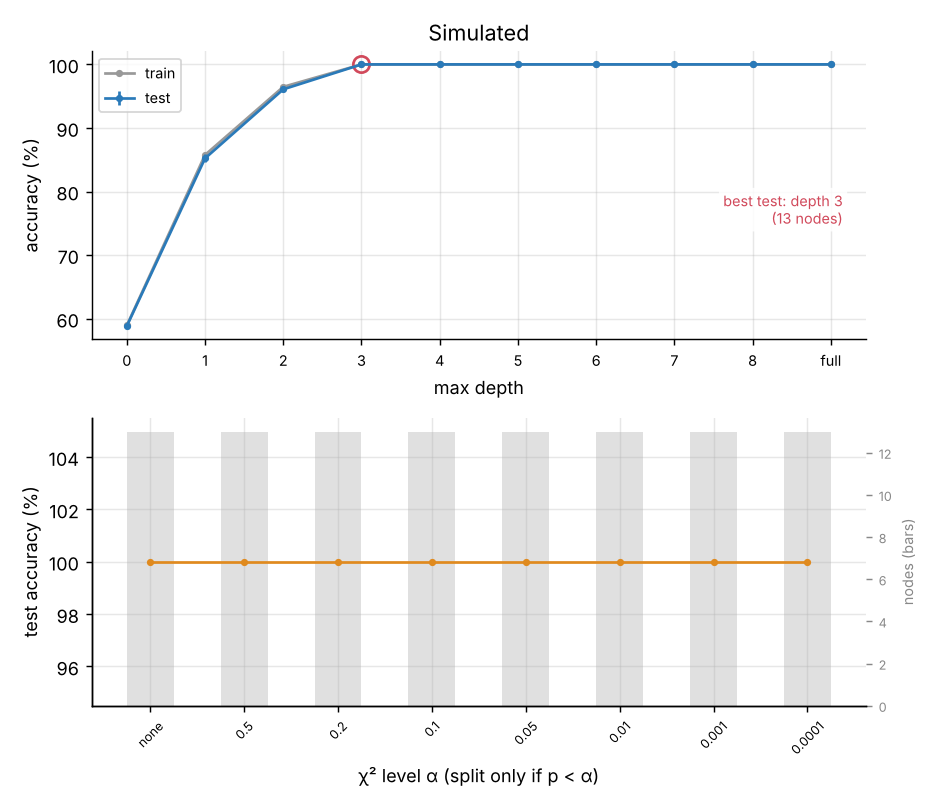

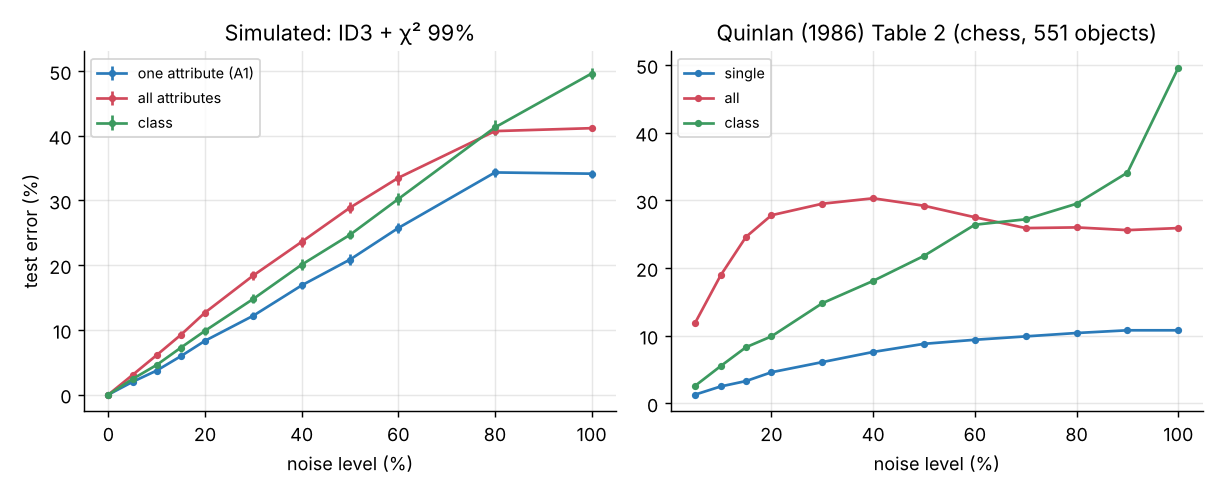

,criterion,id_code_tests,accuracy,acc_se,nodes
0,gain,1.0,0.9553,0.0019,171.45
1,gain ratio,0.0,1.0000,0.0000,13.00
2,"gain, binary subsets",1.0,0.9772,0.0037,12.70


,attribute,values,gain,IV,gain_ratio
0,A1,3,0.5501,1.5833,0.3474
1,id_code,142,0.3268,6.9471,0.0470
2,A2,3,0.1049,1.5818,0.0663
3,A4,3,0.0083,1.5825,0.0053


In [13]:
print(open('results/s1_sim_recovery.txt').read())
with ProcessPoolExecutor() as pool:
    E.sanity_checks(pool, REPS)
display(Image('figures/e3_depth_alpha_sim.png')); display(Image('figures/e4_noise_sim.png'))
display(E.e6_gain_bias(REPS)); display(pd.read_csv('results/e6_root_scores.csv').head(4))

**Reading.**
* **Recovery.** ID3 recovers the generating tree exactly.
* **Noise patterns.** The Table 2 patterns appear with known truth, and depth 3 is the right depth.
* **Gain bias.** An irrelevant 150-valued `id_code` has the second-largest gain, because it shatters the data. The gain criterion uses it in a subtree (172 nodes, 95.5 %). The gain ratio never does (13 nodes, 100 %).

## 10. Conclusions
1. The implementation reproduces the paper exactly, recovers a known tree, and passes 15 tests of the paper's claims.
2. **Depth control:** restricting the tree helps exactly when the data are noisy (votes, Ljubljana) and hurts on noise-free concepts (chess, car). The χ² test automates that choice but is too strict in small nodes.
3. **Noise:** the three degradation patterns of Table 2 reappear on real data. The χ² test keeps trees small and their error lower.
4. **Section 7 matters:** binary subset tests remove ID3's fragmentation problem and make it competitive with CART on every dataset. Thresholds handle continuous attributes. The gain ratio removes the many-values bias.
5. **Departures from the paper (labelled):** formulas for K ≥ 2 classes; `max_depth`; a CART baseline; train/test splits instead of corrupting the whole set twice; public datasets, because the paper's chess files are not public.